In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
import kagglehub
from pathlib import Path

# Downloaded once to the kagglehub cache (~/.cache/kagglehub), outside the repo
DATA_DIR = Path(kagglehub.dataset_download("gauravtopre/bank-customer-churn-dataset"))

C:\Users\jorda\Code\ml-notebooks\courses\deep-learning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
data = pd.read_csv(DATA_DIR / "Bank Customer Churn Prediction.csv")
data.head()
data.shape

(10000, 12)

In [4]:
data = data.drop(columns=["customer_id", "gender", "country"])

x = data.drop(columns=["churn"])
y = data["churn"]

In [5]:
scaler = StandardScaler()
x = scaler.fit_transform(x)

x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.4, random_state=42)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42)

In [6]:
model = tf.keras.Sequential([
    tf.keras.layers.Dense(128, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(0.005), input_shape=(x_train.shape[1],)),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(64, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(0.005)),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(32, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(0.005)),
    tf.keras.layers.Dense(1, activation="sigmoid")
])


C:\Users\jorda\Code\ml-notebooks\courses\deep-learning\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=["accuracy"])

In [8]:
history = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=100, batch_size=32)

Epoch 1/100


  1/188 ━━━━━━━━━━━━━━━━━━━━ 2:31 811ms/step - accuracy: 0.6250 - loss: 1.4097

 49/188 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7902 - loss: 1.1721    

 99/188 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7948 - loss: 1.0671

151/188 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7980 - loss: 0.9859

188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7943 - loss: 0.9463 - val_accuracy: 0.8205 - val_loss: 0.7153


... (643 outputs left out)

 63/188 ━━━━━━━━━━━━━━━━━━━━ 0s 815us/step - accuracy: 0.8472 - loss: 0.3927

125/188 ━━━━━━━━━━━━━━━━━━━━ 0s 814us/step - accuracy: 0.8460 - loss: 0.3939

188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 811us/step - accuracy: 0.8452 - loss: 0.3936

188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8452 - loss: 0.3936 - val_accuracy: 0.8590 - val_loss: 0.3805


In [9]:
predictions = model.predict(x_test[:5])
print(predictions)

for p in predictions:
    if p >= 0.5:
        print(1)
    else:
        print(0)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


[[0.26164186]
 [0.15517206]
 [0.01723668]
 [0.03809149]
 [0.09567101]]
0
0
0
0
0


In [10]:
loss, accuracy = model.evaluate(x_test, y_test)
print(loss, accuracy)

 1/63 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8750 - loss: 0.3994

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 875us/step - accuracy: 0.8520 - loss: 0.3886


0.3885822892189026 0.8519999980926514


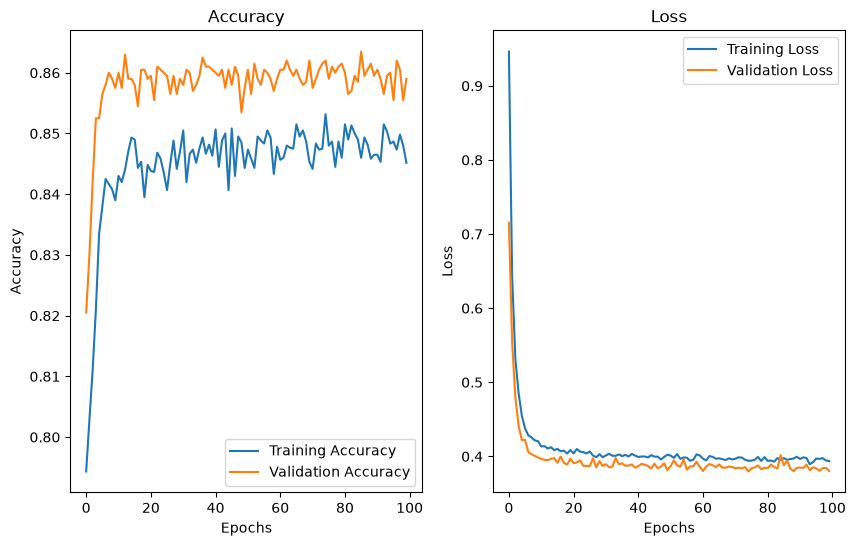

In [11]:
plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()